In [3]:
# import libraries and setups 
import os
import json
import re
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

# --- Paths ---
DATA_RAW     = Path(r"C:\Users\Admin\Endometriosis\Glenda")
CLASSES_DIR  = DATA_RAW / "Glenda_v1.5_classes"
FRAMES_DIR   = CLASSES_DIR / "frames"
ANNOTS_DIR   = CLASSES_DIR / "annots"
COCO_PATH    = CLASSES_DIR / "coco.json"

PROJECT_ROOT = Path(r"C:\Users\Admin\Documents\glenda-lesion-localisation")
MANIFEST_DIR = PROJECT_ROOT / "data_manifests"
INTERIM_DIR  = PROJECT_ROOT / "data" / "interim"

# Output folders
IMAGES_OUT   = INTERIM_DIR / "images_512"
MASKS_MC_OUT = INTERIM_DIR / "masks_multiclass"
MASKS_BI_OUT = INTERIM_DIR / "masks_binary"
COCO_OUT     = INTERIM_DIR / "coco_annotations"

for d in [IMAGES_OUT, MASKS_MC_OUT, MASKS_BI_OUT, COCO_OUT]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Frames dir:  {FRAMES_DIR}  (exists: {FRAMES_DIR.exists()})")
print(f"Annots dir:  {ANNOTS_DIR}  (exists: {ANNOTS_DIR.exists()})")
print(f"Output root: {INTERIM_DIR}")

Frames dir:  C:\Users\Admin\Endometriosis\Glenda\Glenda_v1.5_classes\frames  (exists: True)
Annots dir:  C:\Users\Admin\Endometriosis\Glenda\Glenda_v1.5_classes\annots  (exists: True)
Output root: C:\Users\Admin\Documents\glenda-lesion-localisation\data\interim


In [4]:
# load labels colors and COCO 
# Read class names and colours
labels = [line.strip() for line in (CLASSES_DIR / "labels.txt").read_text().splitlines() if line.strip()]
colors = []
for line in (CLASSES_DIR / "colors.txt").read_text().splitlines():
    if line.strip():
        colors.append(tuple(int(x) for x in line.split()))

print("Labels and colours:\n")
for i, (lab, col) in enumerate(zip(labels, colors)):
    print(f"  class {i}: {lab:35s}  RGB={col}")

# Load COCO
with open(COCO_PATH) as f:
    coco = json.load(f)

cat_id_to_name = {c["id"]: c["name"] for c in coco["categories"]}
img_id_to_meta = {img["id"]: img for img in coco["images"]}

# Build a mapping: RGB colour -> class index (0-4)
COLOR_TO_CLASS = {col: i for i, col in enumerate(colors)}
CLASS_NAMES    = labels
print("\nColour-to-class mapping built.")
print(f"Number of classes (including background): {len(CLASS_NAMES)}")

Labels and colours:

  class 0: background                           RGB=(0, 0, 0)
  class 1: 6.1.1.1_Endo-Peritoneum              RGB=(190, 62, 204)
  class 2: 6.1.1.2_Endo-Ovar                    RGB=(93, 89, 254)
  class 3: 6.1.1.3_Endo-TIE                     RGB=(145, 210, 138)
  class 4: 6.1.1.4_Endo-Uterus                  RGB=(238, 236, 50)

Colour-to-class mapping built.
Number of classes (including background): 5


In [5]:
# load a sample mask and check colors 
# Take the first image in the manifest
with open(MANIFEST_DIR / "frame_metadata.csv") as f:
    manifest = pd.read_csv(f)

sample = manifest.iloc[0]
sample_name = sample["file_name"]
mask_stem   = Path(sample_name).stem

# Mask is same base name with .png
mask_path = ANNOTS_DIR / f"{mask_stem}.png"
img_path  = FRAMES_DIR / f"{mask_stem}.jpg"

print(f"Image: {img_path.name}  (exists: {img_path.exists()})")
print(f"Mask:  {mask_path.name}  (exists: {mask_path.exists()})")

img = np.array(Image.open(img_path).convert("RGB"))
msk = np.array(Image.open(mask_path).convert("RGB"))

print(f"\nImage shape: {img.shape}, dtype: {img.dtype}")
print(f"Mask  shape: {msk.shape}, dtype: {msk.dtype}")

# Find unique colours in the mask
unique_colors, counts = np.unique(msk.reshape(-1, 3), axis=0, return_counts=True)
print(f"\nUnique colours in mask: {len(unique_colors)}")
order = np.argsort(-counts)
for i in order[:10]:
    col = tuple(int(v) for v in unique_colors[i])
    print(f"  RGB{col}  ->  {counts[i]:>8d} pixels")

Image: c_100_v_(video_3062.mp4)_f_1458.jpg  (exists: True)
Mask:  c_100_v_(video_3062.mp4)_f_1458.png  (exists: True)

Image shape: (360, 640, 3), dtype: uint8
Mask  shape: (360, 640, 3), dtype: uint8

Unique colours in mask: 146
  RGB(0, 0, 0)  ->    228110 pixels
  RGB(238, 236, 50)  ->      2010 pixels
  RGB(36, 36, 8)  ->        21 pixels
  RGB(229, 227, 48)  ->        11 pixels
  RGB(74, 74, 16)  ->         8 pixels
  RGB(237, 235, 50)  ->         8 pixels
  RGB(111, 110, 23)  ->         8 pixels
  RGB(236, 234, 50)  ->         6 pixels
  RGB(95, 94, 20)  ->         5 pixels
  RGB(3, 3, 1)  ->         5 pixels


In [6]:
# verify all masks
# Check that all 373 masks only contain the 5 expected colours (or their nearest matches)
expected = set(tuple(c) for c in colors)
problems = []

for f in tqdm(sorted(ANNOTS_DIR.glob("*.png"))):
    arr = np.array(Image.open(f).convert("RGB"))
    uniq = set(tuple(int(v) for v in c) for c in np.unique(arr.reshape(-1, 3), axis=0))
    extra = uniq - expected
    if extra:
        problems.append((f.name, sorted(extra)[:5]))

print(f"Masks checked:  {len(list(ANNOTS_DIR.glob('*.png')))}")
print(f"Masks with unexpected colours: {len(problems)}")
if problems:
    print("\nFirst 5 problematic masks:")
    for name, extras in problems[:5]:
        print(f"  {name}: extra colours {extras}")

  0%|          | 0/373 [00:00<?, ?it/s]

Masks checked:  373
Masks with unexpected colours: 373

First 5 problematic masks:
  c_100_v_(video_3062.mp4)_f_1458.png: extra colours [(1, 1, 0), (2, 2, 0), (3, 3, 1), (4, 4, 1), (5, 5, 1)]
  c_102_v_(video_3119.mp4)_f_1311.png: extra colours [(1, 0, 1), (1, 0, 2), (2, 1, 2), (3, 1, 3), (4, 1, 4)]
  c_102_v_(video_3119.mp4)_f_185.png: extra colours [(1, 0, 1), (1, 0, 2), (2, 1, 2), (3, 1, 3), (4, 1, 4)]
  c_102_v_(video_3124.mp4)_f_97.png: extra colours [(1, 0, 1), (1, 0, 2), (2, 1, 2), (3, 1, 3), (4, 1, 4)]
  c_102_v_(video_3130.mp4)_f_0.png: extra colours [(1, 0, 1), (1, 0, 2), (2, 1, 2), (3, 1, 3), (4, 1, 4)]


In [7]:
# colour to class label map conversion 
import cv2
import numpy as np
from collections import defaultdict

# Group annotations by image_id for fast lookup
anns_per_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_per_image[ann["image_id"]].append(ann)

def generate_mask_from_coco(image_id, orig_w, orig_h):
    """
    Create a multi-class mask directly from COCO polygons using OpenCV.
    0 = background, 1 = Peritoneum, 2 = Ovary, 3 = TIE, 4 = Uterus.
    """
    mask_mc = np.zeros((orig_h, orig_w), dtype=np.uint8)
    
    for ann in anns_per_image.get(image_id, []):
        cat_id = ann["category_id"]
        segmentation = ann["segmentation"]
        
        # COCO segmentation can be a list of polygons
        if isinstance(segmentation, list):
            for poly in segmentation:
                pts = np.array(poly, dtype=np.int32).reshape(-1, 2)
                cv2.fillPoly(mask_mc, [pts], color=cat_id)
        # If it's RLE (dict), we would need pycocotools, but GLENDA uses polygons
        elif isinstance(segmentation, dict):
            print("Warning: RLE segmentation encountered. This frame might need pycocotools.")
            
    return mask_mc

print("COCO mask generator (using OpenCV) is ready.")

COCO mask generator (using OpenCV) is ready.


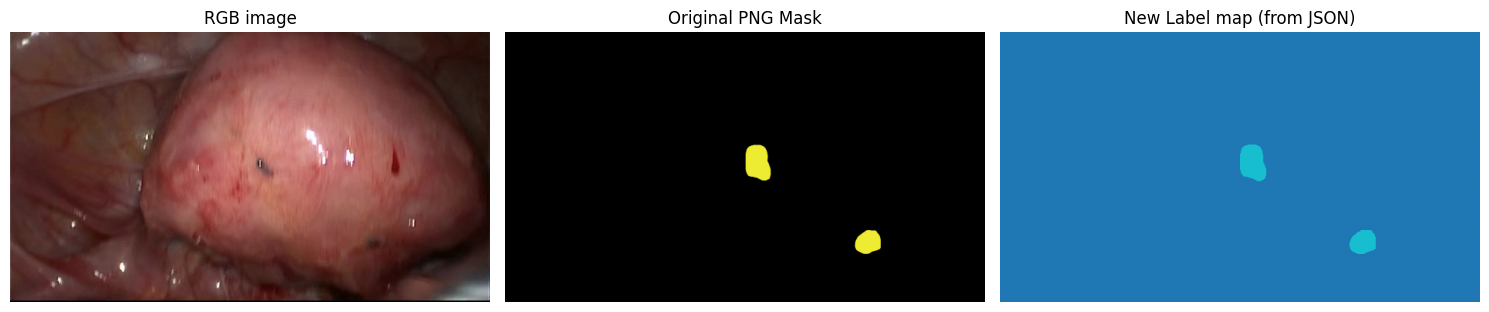


Sample name: c_100_v_(video_3062.mp4)_f_1458.jpg
Classes present in this frame: ['6.1.1.4_Endo-Uterus']
Unique integers in new mask: [0 4]


In [9]:
# visual check of a sample
# Re-run the sample setup
sample = manifest.iloc[0]
sample_name = sample["file_name"]
sample_stem = Path(sample_name).stem

img_path  = FRAMES_DIR / f"{sample_stem}.jpg"
mask_path = ANNOTS_DIR / f"{sample_stem}.png"

img = np.array(Image.open(img_path).convert("RGB"))
msk_rgb = np.array(Image.open(mask_path).convert("RGB"))

# Generate the NEW label map directly from the COCO json
orig_h, orig_w = img.shape[:2]
label_sample = generate_mask_from_coco(sample["image_id"], orig_w, orig_h)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img)
axes[0].set_title("RGB image")
axes[0].axis("off")

axes[1].imshow(msk_rgb)
axes[1].set_title("Original PNG Mask")
axes[1].axis("off")

axes[2].imshow(label_sample, cmap="tab10", vmin=0, vmax=4)
axes[2].set_title("New Label map (from JSON)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

unique = np.unique(label_sample)
print("\nSample name:", sample_name)
print("Classes present in this frame:", [CLASS_NAMES[i] for i in unique if i != 0])
print("Unique integers in new mask:", unique)

In [17]:
# batch preprocess images and masks 
IMG_SIZE = 512
NEG_DIR  = DATA_RAW / "no_pathology"

def resize_pair(img_pil, mask_np, size):
    img_resized  = img_pil.resize((size, size), Image.BILINEAR)
    mask_resized = Image.fromarray(mask_np).resize((size, size), Image.NEAREST)
    return img_resized, np.array(mask_resized)

# 1. Process Annotated Frames
print("Processing annotated frames...")
processed_ann = 0
for _, row in tqdm(manifest.iterrows(), total=len(manifest)):
    stem = Path(row["file_name"]).stem
    img_path  = FRAMES_DIR / f"{stem}.jpg"
    
    if not img_path.exists():
        continue

    img_pil  = Image.open(img_path).convert("RGB")
    orig_w, orig_h = img_pil.size
    
    label_mc = generate_mask_from_coco(row["image_id"], orig_w, orig_h)
    img_r, mask_r = resize_pair(img_pil, label_mc, IMG_SIZE)

    img_r.save(IMAGES_OUT / f"{stem}.png")
    Image.fromarray(mask_r.astype(np.uint8)).save(MASKS_MC_OUT / f"{stem}.png")
    binary = (mask_r > 0).astype(np.uint8) * 255
    Image.fromarray(binary).save(MASKS_BI_OUT / f"{stem}.png")
    processed_ann += 1

# 2. Process Negative Frames
print(f"\nProcessing negative frames from {NEG_DIR}...")
neg_images = list(NEG_DIR.rglob("*.jpg"))
processed_neg = 0

for img_path in tqdm(neg_images):
    # Create a unique name: parent folder + frame name
    video_folder = img_path.parent.name
    unique_stem = f"{video_folder}_{img_path.stem}"
    
    img_pil = Image.open(img_path).convert("RGB")
    orig_w, orig_h = img_pil.size
    
    # Empty mask (all background)
    mask_mc = np.zeros((orig_h, orig_w), dtype=np.uint8)
    img_r, mask_r = resize_pair(img_pil, mask_mc, IMG_SIZE)

    # Save using the unique name
    img_r.save(IMAGES_OUT / f"{unique_stem}.png")
    Image.fromarray(mask_r).save(MASKS_MC_OUT / f"{unique_stem}.png")
    binary = (mask_r > 0).astype(np.uint8) * 255
    Image.fromarray(binary).save(MASKS_BI_OUT / f"{unique_stem}.png")
    processed_neg += 1

print(f"\nProcessed {processed_ann} annotated and {processed_neg} negative frames.")
print(f"Total images in folder: {len(list(IMAGES_OUT.glob('*.png')))}")

Processing annotated frames...


  0%|          | 0/373 [00:00<?, ?it/s]


Processing negative frames from C:\Users\Admin\Endometriosis\Glenda\no_pathology...


  0%|          | 0/13438 [00:00<?, ?it/s]


Processed 373 annotated and 13438 negative frames.
Total images in folder: 17182


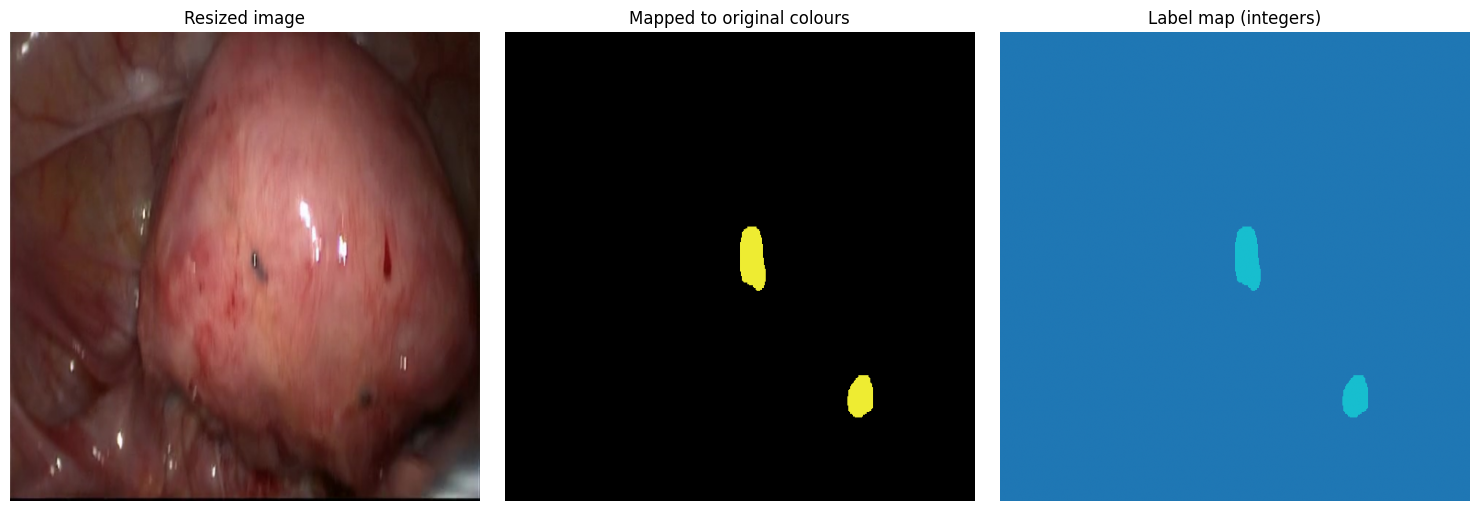

Unique classes in this frame: [0 4]


In [11]:
# verify the output 
# Pick a sample to verify
stem = manifest.iloc[0]["file_name"].replace(".jpg", "")
img_check  = np.array(Image.open(IMAGES_OUT / f"{stem}.png"))
mask_check = np.array(Image.open(MASKS_MC_OUT / f"{stem}.png"))

# Map integers back to RGB for visualization
colors = [(0,0,0), (190, 62, 204), (93, 89, 254), (145, 210, 138), (238, 236, 50)]
mask_rgb = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
for i, col in enumerate(colors):
    mask_rgb[mask_check == i] = col

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_check); axes[0].set_title("Resized image"); axes[0].axis("off")
axes[1].imshow(mask_rgb); axes[1].set_title("Mapped to original colours"); axes[1].axis("off")
axes[2].imshow(mask_check, cmap="tab10", vmin=0, vmax=4); axes[2].set_title("Label map (integers)"); axes[2].axis("off")
plt.tight_layout()
plt.show()

print("Unique classes in this frame:", np.unique(mask_check))


In [12]:
# extract instance annotations for maskr-cnn/yolo
# Scale factor per image (original -> 512)
def scale_coco(coco: dict, target_size: int = 512) -> dict:
    out = {k: v for k, v in coco.items()}
    new_images = []
    for img in coco["images"]:
        w = img["width"]
        h = img["height"]
        sx = target_size / w
        sy = target_size / h
        new_img = dict(img)
        new_img["width"]  = target_size
        new_img["height"] = target_size
        new_img["orig_width"]  = w
        new_img["orig_height"] = h
        new_img["scale_x"] = sx
        new_img["scale_y"] = sy
        new_images.append(new_img)
    out["images"] = new_images

    img_scales = {img["id"]: (img["scale_x"], img["scale_y"]) for img in new_images}

    new_anns = []
    for ann in coco["annotations"]:
        new_ann = dict(ann)
        sx, sy = img_scales[ann["image_id"]]
        # Rescale bbox
        if "bbox" in ann:
            x, y, w, h = ann["bbox"]
            new_ann["bbox"] = [x * sx, y * sy, w * sx, h * sy]
        # Rescale polygon segmentation
        if "segmentation" in ann and isinstance(ann["segmentation"], list):
            new_segs = []
            for poly in ann["segmentation"]:
                poly = np.array(poly, dtype=float).reshape(-1, 2)
                poly[:, 0] *= sx
                poly[:, 1] *= sy
                new_segs.append(poly.flatten().tolist())
            new_ann["segmentation"] = new_segs
        if "area" in ann:
            new_ann["area"] = ann["area"] * sx * sy
        new_anns.append(new_ann)
    out["annotations"] = new_anns
    return out


coco_512 = scale_coco(coco, target_size=512)

with open(COCO_OUT / "annotations_512.json", "w") as f:
    json.dump(coco_512, f)

print(f"Saved scaled COCO to {COCO_OUT / 'annotations_512.json'}")
print(f"Images:      {len(coco_512['images'])}")
print(f"Annotations: {len(coco_512['annotations'])}")
print(f"Categories:  {len(coco_512['categories'])}")

Saved scaled COCO to C:\Users\Admin\Documents\glenda-lesion-localisation\data\interim\coco_annotations\annotations_512.json
Images:      373
Annotations: 628
Categories:  4


In [18]:
# load negatives manifest
NEG_DIR = DATA_RAW / "no_pathology"

neg_records = []
for f in NEG_DIR.rglob("*.jpg"):
    video_folder = f.parent.name # e.g., "v_2506_s_0-95"
    frame_name = f.stem          # e.g., "f_0"
    
    # Extract video ID, e.g., "v_2506" from "v_2506_s_0-95"
    video_id = video_folder.split("_s_")[0] if "_s_" in video_folder else video_folder
    frame_num = int(frame_name.replace("f_", "")) if frame_name.startswith("f_") else 0
    
    unique_stem = f"{video_folder}_{frame_name}"
    
    neg_records.append({
        "image_id": -1, 
        "file_name": f"{unique_stem}.png", # Match the new saved name
        "case_id": video_id,               # Use video ID as case ID for negatives
        "video_id": video_id,
        "frame_num": frame_num,
        "width": IMG_SIZE,
        "height": IMG_SIZE,
        "n_annotations": 0,
        "classes": "no_pathology",
        "total_area": 0
    })

neg_df = pd.DataFrame(neg_records)
full_manifest = pd.concat([manifest, neg_df], ignore_index=True)

full_manifest.to_csv(MANIFEST_DIR / "full_manifest.csv", index=False)

print(f"Annotated frames: {len(manifest)}")
print(f"Negative frames:  {len(neg_df)}")
print(f"Total frames:     {len(full_manifest)}")
print(f"Total unique cases/videos: {full_manifest['case_id'].nunique()}")


Annotated frames: 373
Negative frames:  13438
Total frames:     13811
Total unique cases/videos: 122


In [19]:
# generate 5 fold case grouped splits
import random

def make_folds(case_ids, n_folds=5, seed=42):
    rng = random.Random(seed)
    cases = sorted(case_ids)
    rng.shuffle(cases)
    folds = [[] for _ in range(n_folds)]
    for i, c in enumerate(cases):
        folds[i % n_folds].append(c)
    return folds

def build_splits(df, n_folds=5, n_seeds=3):
    all_cases = sorted(df["case_id"].unique())
    rounds = []
    for s in range(n_seeds):
        seed = 42 + s * 100
        folds = make_folds(all_cases, n_folds=n_folds, seed=seed)
        rounds.append({"seed": seed, "folds": [sorted(f) for f in folds]})
    return rounds

splits = build_splits(full_manifest, n_folds=5, n_seeds=3)

split_path = MANIFEST_DIR / "cv5_splits_full.json"
with open(split_path, "w") as f:
    json.dump({
        "n_folds": 5,
        "n_seeds": 3,
        "annotated_only": False,
        "rounds": splits,
    }, f, indent=2)

print(f"Saved splits to: {split_path}")
print(f"Total cases split into 5 folds: {full_manifest['case_id'].nunique()}")


Saved splits to: C:\Users\Admin\Documents\glenda-lesion-localisation\data_manifests\cv5_splits_full.json
Total cases split into 5 folds: 122


In [20]:
# report per fold class counts
def count_class_per_case(df):
    out = defaultdict(Counter)
    for _, row in df.iterrows():
        cls_list = row["classes"].split(";") if isinstance(row["classes"], str) else []
        if not cls_list:
             cls_list = ["no_pathology"]
        for c in cls_list:
            out[row["case_id"]][c] += 1
    return out

from collections import Counter
case_counts = count_class_per_case(full_manifest)
all_cases = set(full_manifest["case_id"].unique())

rows = []
for r_i, rnd in enumerate(splits):
    for f_i, fold_cases in enumerate(rnd["folds"]):
        val = set(fold_cases)
        train = all_cases - val
        for cls in ["6.1.1.1_Endo-Peritoneum", "6.1.1.2_Endo-Ovar", 
                    "6.1.1.3_Endo-TIE", "6.1.1.4_Endo-Uterus", "no_pathology"]:
            val_n = sum(case_counts[c][cls] for c in val)
            train_n = sum(case_counts[c][cls] for c in train)
            rows.append({
                "round": r_i, "seed": rnd["seed"], "fold": f_i, "class": cls,
                "train_cases": len(train), "val_cases": len(val),
                "train_annotations": train_n, "val_annotations": val_n,
            })

fold_df = pd.DataFrame(rows)
fold_df.to_csv(MANIFEST_DIR / "fold_class_counts_full.csv", index=False)

# Print just Round 0 to check
print(fold_df[fold_df["round"] == 0].to_string(index=False))
print(f"\nSaved to: {MANIFEST_DIR / 'fold_class_counts_full.csv'}")

 round  seed  fold                   class  train_cases  val_cases  train_annotations  val_annotations
     0    42     0 6.1.1.1_Endo-Peritoneum           97         25                193               64
     0    42     0       6.1.1.2_Endo-Ovar           97         25                 45                8
     0    42     0        6.1.1.3_Endo-TIE           97         25                 44               11
     0    42     0     6.1.1.4_Endo-Uterus           97         25                 15                2
     0    42     0            no_pathology           97         25              11080             2358
     0    42     1 6.1.1.1_Endo-Peritoneum           97         25                208               49
     0    42     1       6.1.1.2_Endo-Ovar           97         25                 39               14
     0    42     1        6.1.1.3_Endo-TIE           97         25                 41               14
     0    42     1     6.1.1.4_Endo-Uterus           97         25       

In [16]:
# how negative files are named
NEG_DIR = DATA_RAW / "no_pathology"
neg_files = list(NEG_DIR.rglob("*.jpg"))

print(f"Total negatives found: {len(neg_files)}")
print("\nFirst 15 negative file paths (relative to no_pathology):")
for f in neg_files[:15]:
    print(f.relative_to(NEG_DIR))

Total negatives found: 13438

First 15 negative file paths (relative to no_pathology):
frames\v_2506_s_0-95\f_0.jpg
frames\v_2506_s_0-95\f_1.jpg
frames\v_2506_s_0-95\f_10.jpg
frames\v_2506_s_0-95\f_11.jpg
frames\v_2506_s_0-95\f_12.jpg
frames\v_2506_s_0-95\f_13.jpg
frames\v_2506_s_0-95\f_14.jpg
frames\v_2506_s_0-95\f_15.jpg
frames\v_2506_s_0-95\f_16.jpg
frames\v_2506_s_0-95\f_17.jpg
frames\v_2506_s_0-95\f_18.jpg
frames\v_2506_s_0-95\f_19.jpg
frames\v_2506_s_0-95\f_2.jpg
frames\v_2506_s_0-95\f_20.jpg
frames\v_2506_s_0-95\f_21.jpg


In [21]:
# clean up of extra files 
# Clean up extra files generated from the previous buggy run
valid_stems = set(full_manifest["file_name"].apply(lambda x: Path(x).stem))
for folder in [IMAGES_OUT, MASKS_MC_OUT, MASKS_BI_OUT]:
    count_removed = 0
    for f in folder.glob("*.png"):
        if f.stem not in valid_stems:
            f.unlink()
            count_removed += 1
    print(f"Removed {count_removed} leftover files from {folder.name}")

Removed 3371 leftover files from images_512
Removed 3371 leftover files from masks_multiclass
Removed 3371 leftover files from masks_binary
